# Stage 03 — Outlier Detection & Treatment

## Objective

Compare marginal, isolation, local-density and density-clustering anomaly definitions,
then assess agreement and the distributional consequences of hypothetical removal.
No verified outlier labels are available; detection rates cannot rank accuracy.

## Methodology

Use all 8,173 training records and 69 numerical candidates. IQR and Z-score use original
observed values; missing values are never flagged. The multivariate methods share the
same train-fitted kNN10/observed-SD representation, with known cells restored exactly.
This input distinction is explicit: the comparison does not isolate algorithm alone.

| Detector | Fixed settings |
|---|---|
| IQR / Z-score | Linear quartiles; 1.5×IQR; strict abs(z)>3 with ddof=0; ANY observed feature |
| Isolation Forest | contamination=.01/.05/.10; 100 trees; max_samples=auto; seed=42 |
| LOF | neighbors=10/20/50; contamination=auto; novelty=False; brute Euclidean |
| DBSCAN | min_samples=20 including self; one training-only chord-elbow eps; brute Euclidean |

$$
IQR_j=Q_{3,j}-Q_{1,j},\qquad
L_j=Q_{1,j}-1.5IQR_j,\qquad U_j=Q_{3,j}+1.5IQR_j.
$$

$$
F^{IQR}_{ij}=\mathbf{1}\{x_{ij}\text{ observed and }(x_{ij}<L_j\text{ or }x_{ij}>U_j)\},\qquad
R^{IQR}_i=\mathbf{1}\{\sum_j F^{IQR}_{ij}\geq1\}.
$$

$$
z_{ij}=\frac{x_{ij}-\mu_{j,train}}{\sigma_{j,train}},\qquad
F^{Z}_{ij}=\mathbf{1}\{x_{ij}\text{ observed and }|z_{ij}|>3\},\qquad
R^{Z}_i=\mathbf{1}\{\sum_jF^{Z}_{ij}\geq1\}.
$$

$$
s(x)=2^{-E[h(x)]/c(\psi)},\qquad
c(\psi)=2H_{\psi-1}-2(\psi-1)/\psi.
$$

$$
\operatorname{reach}_k(p,o)=\max\{d_k(o),d(p,o)\},\quad
\operatorname{lrd}_k(p)=\left[\frac1{|N_k(p)|}\sum_{o\in N_k(p)}\operatorname{reach}_k(p,o)\right]^{-1},\quad
\operatorname{LOF}_k(p)=\frac1{|N_k(p)|}\sum_{o\in N_k(p)}\frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)}.
$$

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$

$$
D_{n,m}=\sup_x|F_n(x)-G_m(x)|.
$$

DBSCAN eps uses the first maximum of normalized sorted rank minus normalized k-distance;
its zero/flat fallbacks are fixed, and a measured allocation guard precedes fitting.
Jaccard uses aligned training identities; empty/empty is undefined. Compare original and
independently retained **observed** values with KS D for all 9×69 policies/features.
Because retained samples are nested and ZIPs repeat, KS p-values are nominal references,
not calibrated significance or a deletion criterion.

## Implementation

This notebook rebuilds only the shared preparation from raw training rows; it does not
execute the imputation benchmark or earlier notebooks. Threshold/detector code and seeds
are retained. Preliminary univariate plots and full audit tables are folded. Synthetic fixtures are
in `tests/`; the complete nine-configuration comparison is the main result.

In [1]:
from pathlib import Path
import hashlib
import re
import subprocess
import sys
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'myst.yml').is_file() and (p / 'src/validate_dataset.py').is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / '.venv':
    raise RuntimeError('Start in the repository and use the hcmus-wids .venv kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.tabular_data import load_data, split_data, numerical_columns, numeric_audit, prepare_numeric_training, memory_gib, CLINICAL_FIELDS, CATEGORICAL_FEATURES, REPRESENTATIVE_FEATURES, KNN_MEMORY_MIB

DATA_PATH = ROOT / 'data/raw/training.csv'
ID, TARGET, ZIP = 'patient_id', 'DiagPeriodL90D', 'patient_zip3'
df, raw_sha_before = load_data(ROOT)
train_index, validation_index, reserved_index = split_data(df)
clinical_fields = CLINICAL_FIELDS.copy()
FEATURES = REPRESENTATIVE_FEATURES.copy()
forbidden = clinical_fields | {ID, TARGET, ZIP, *CATEGORICAL_FEATURES, 'patient_gender'}
numerical_candidates = numerical_columns(df)
numerical_eligibility, bounded_share_features = numeric_audit(df, train_index, validation_index)
EXPANDED_FEATURES = numerical_candidates.copy()
air_features = {'Ozone', 'PM25', 'N02'}
stage03_adopted_training_rows = train_index.copy()  # Preserved keep-all decision before this stage's intervention.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':140})

preparation_start = perf_counter()
(outlier_train_original, outlier_original_missing, expanded_scaler, shared_knn,
 expanded_train_z, outlier_common_train_raw, outlier_common_train_z) = prepare_numeric_training(df, train_index, numerical_candidates)
outlier_features = numerical_candidates.copy()
outlier_common_imputed_mask = outlier_original_missing.copy(deep=True)
outlier_preparation_seconds = perf_counter()-preparation_start

memory_total, memory_reclaimable = memory_gib()

### Shared observed/complete training views

In [2]:
outlier_features = list(numerical_candidates)
outlier_train_original = df.loc[train_index, outlier_features].copy(deep=True)
outlier_original_missing = outlier_train_original.isna()

outlier_quartiles = outlier_train_original.quantile([.25, .75], interpolation="linear").T
outlier_audit_iqr = outlier_quartiles[.75] - outlier_quartiles[.25]
outlier_audit_sd = outlier_train_original.std(ddof=0)
outlier_feature_audit = pd.DataFrame({
    "Storage dtype": outlier_train_original.dtypes.astype(str),
    "Semantic role": numerical_eligibility["Semantic role"],
    "Observed training N": outlier_train_original.count(),
    "Natural missing N": outlier_original_missing.sum(),
    "Natural missing % (train)": outlier_original_missing.mean()*100,
    "Distinct observed N": outlier_train_original.nunique(),
    "Constant observed": outlier_train_original.nunique().eq(1),
    "Zero IQR": outlier_audit_iqr.eq(0), "Zero SD": outlier_audit_sd.eq(0),
    "Skewness (observed train)": outlier_train_original.skew(),
    "Semantic / timing note": numerical_eligibility["Reason"]})
outlier_feature_audit["High |skew| > 1 (descriptive)"] = outlier_feature_audit["Skewness (observed train)"].abs().gt(1)
outlier_feature_audit["IQR eligible"] = outlier_train_original.count().ge(4) & outlier_audit_iqr.gt(0) & np.isfinite(outlier_audit_iqr)
outlier_feature_audit["Z-score eligible"] = outlier_train_original.count().ge(2) & outlier_audit_sd.gt(0) & np.isfinite(outlier_audit_sd)
outlier_feature_audit["Redundancy review"] = "Retained; no correlation-based exclusion"
for columns, note in [
    (["male", "female"], "Complementary area shares; potentially repeated triggers"),
    (["education_bachelors", "education_graduate", "education_college_or_above"], "Overlapping education summaries retained"),
    (["income_household_100_to_150", "income_household_150_over", "income_household_six_figure"], "Overlapping income shares retained")]:
    outlier_feature_audit.loc[columns, "Redundancy review"] = note
outlier_feature_audit.index = outlier_feature_audit.index.copy().rename("Feature")
display(HTML('<details><summary>Outlier eligibility audit — all 69 numerical candidates</summary>'
    '<div style="overflow:auto;max-height:32rem">'+outlier_feature_audit.to_html(float_format="{:.4f}".format)+'</div></details>'))

display(pd.Series({"Training records": len(outlier_train_original), "Numerical candidates": len(outlier_features),
    "IQR eligible": int(outlier_feature_audit["IQR eligible"].sum()),
    "Z-score eligible": int(outlier_feature_audit["Z-score eligible"].sum()),
    "Natural cells imputed only in Part 2 preparation": int(outlier_common_imputed_mask.to_numpy().sum()),
    "Shared training preparation seconds": outlier_preparation_seconds,
    "Dense train x train distance upper bound MiB": len(train_index)**2*8/1024**2,
    "Chunk budget MiB (not a total RAM cap)": KNN_MEMORY_MIB}).to_frame("Preparation"))

,Storage dtype,Semantic role,Observed training N,Natural missing N,Natural missing % (train),Distinct observed N,Constant observed,Zero IQR,Zero SD,Skewness (observed train),Semantic / timing note,High |skew| > 1 (descriptive),IQR eligible,Z-score eligible,Redundancy review
Feature,,,,,,,,,,,,,,,
patient_age,int64,Individual age,8173,0,0.0000,67,False,False,False,0.1204,Index/baseline alignment unverified,False,True,True,Retained; no correlation-based exclusion
bmi,float64,Individual BMI,2531,5642,69.0322,1037,False,False,False,0.9304,Post-metastatic; retrospective only,False,True,True,Retained; no correlation-based exclusion
population,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,0.4145,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
density,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,3.7989,Context/reference period unresolved; units vary,True,True,True,Retained; no correlation-based exclusion
age_median,float64,Area numerical summary,8173,0,0.0000,439,False,False,False,0.2867,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
age_under_10,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,0.0294,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_10_to_19,float64,"Area share [0,100]",8173,0,0.0000,440,False,False,False,0.9516,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_20s,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,1.7244,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion
age_30s,float64,"Area share [0,100]",8173,0,0.0000,438,False,False,False,1.1267,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion


,Preparation
Training records,8173.000000
Numerical candidates,69.000000
IQR eligible,69.000000
Z-score eligible,69.000000
Natural cells imputed only in Part 2 preparation,5717.000000
Shared training preparation seconds,1.880896
Dense train x train distance upper bound MiB,509.627754
Chunk budget MiB (not a total RAM cap),128.000000


### IQR

In [3]:
def detect_iqr(frame):
    """Fit linear-quartile fences on observed input values; skip unsupported columns."""
    finite = (frame.isna() | np.isfinite(frame)).all()
    quantiles = frame.loc[:, finite].quantile([.25, .75], interpolation="linear").T.reindex(frame.columns)
    parameters = pd.DataFrame({"Observed N": frame.count(), "Q1": quantiles[.25], "Q3": quantiles[.75]})
    parameters["IQR"] = parameters.Q3 - parameters.Q1
    parameters["Eligible"] = finite & parameters["Observed N"].ge(4) & parameters.IQR.gt(0) & np.isfinite(parameters.IQR)
    parameters["Note"] = np.select([~finite, parameters["Observed N"].lt(4), ~np.isfinite(parameters.IQR), parameters.IQR.le(0)],
        ["NOT EVALUATED: nonfinite observed input", "NOT EVALUATED: fewer than 4 observations",
         "NOT EVALUATED: invalid IQR", "NOT EVALUATED: zero/nonpositive IQR"], default="Eligible")
    parameters["Lower fence"] = (parameters.Q1 - 1.5*parameters.IQR).where(parameters.Eligible)
    parameters["Upper fence"] = (parameters.Q3 + 1.5*parameters.IQR).where(parameters.Eligible)
    flags = (frame.lt(parameters["Lower fence"], axis="columns") | frame.gt(parameters["Upper fence"], axis="columns")) & frame.notna()
    return parameters, flags

iqr_thresholds, iqr_feature_flags = detect_iqr(outlier_train_original)
iqr_flagged_features_per_row = iqr_feature_flags.sum(axis=1).rename("IQR triggered features N")
iqr_observation_flags = iqr_flagged_features_per_row.ge(1).rename("IQR")
iqr_feature_counts = iqr_feature_flags.sum().where(iqr_thresholds.Eligible).rename("IQR flagged N")
iqr_feature_rates = (100*iqr_feature_counts/iqr_thresholds["Observed N"]).rename("IQR flagged % of observed")
iqr_top_feature = iqr_feature_rates.idxmax()
display(HTML(f"<p><strong>IQR result:</strong> {int(iqr_thresholds.Eligible.sum())}/{len(outlier_features)} features evaluated; "
    f"{int(iqr_observation_flags.sum()):,}/{len(train_index):,} training records flagged by ANY feature "
    f"({iqr_observation_flags.mean()*100:.2f}%). Highest feature rate: {iqr_top_feature}, "
    f"{int(iqr_feature_counts[iqr_top_feature])}/{int(iqr_thresholds.loc[iqr_top_feature,'Observed N'])} "
    f"({iqr_feature_rates[iqr_top_feature]:.2f}%). These are diagnostic flags, not confirmed errors.</p>"))

### Z-score

In [4]:
def detect_zscore(frame):
    """Fit observed-value mean/population SD and apply strict |z|>3 without filling NaNs."""
    finite = (frame.isna() | np.isfinite(frame)).all()
    supported = frame.loc[:, finite]
    parameters = pd.DataFrame({"Observed N": frame.count(), "Mean": supported.mean(), "SD (ddof 0)": supported.std(ddof=0)}).reindex(frame.columns)
    parameters["Eligible"] = finite & parameters["Observed N"].ge(2) & parameters["SD (ddof 0)"].gt(0) & np.isfinite(parameters["SD (ddof 0)"])
    parameters["Note"] = np.select([~finite, parameters["Observed N"].lt(2), ~np.isfinite(parameters["SD (ddof 0)"]) | parameters["SD (ddof 0)"].le(0)],
        ["NOT EVALUATED: nonfinite observed input", "NOT EVALUATED: fewer than 2 observations", "NOT EVALUATED: zero/invalid SD"], default="Eligible")
    scores = frame.sub(parameters.Mean, axis="columns").div(parameters["SD (ddof 0)"].where(parameters.Eligible), axis="columns")
    flags = scores.abs().gt(3) & frame.notna()
    return parameters, scores, flags

zscore_parameters, outlier_z_scores, zscore_feature_flags = detect_zscore(outlier_train_original)
zscore_flagged_features_per_row = zscore_feature_flags.sum(axis=1).rename("Z-score triggered features N")
zscore_observation_flags = zscore_flagged_features_per_row.ge(1).rename("Z-score")
zscore_feature_counts = zscore_feature_flags.sum().where(zscore_parameters.Eligible).rename("Z-score flagged N")
zscore_feature_rates = (100*zscore_feature_counts/zscore_parameters["Observed N"]).rename("Z-score flagged % of observed")
zscore_top_feature = zscore_feature_rates.idxmax()
display(HTML(f"<p><strong>Z-score result:</strong> {int(zscore_parameters.Eligible.sum())}/{len(outlier_features)} features evaluated; "
    f"{int(zscore_observation_flags.sum()):,}/{len(train_index):,} training records flagged by ANY feature "
    f"({zscore_observation_flags.mean()*100:.2f}%). Highest feature rate: {zscore_top_feature}, "
    f"{int(zscore_feature_counts[zscore_top_feature])}/{int(zscore_parameters.loc[zscore_top_feature,'Observed N'])} "
    f"({zscore_feature_rates[zscore_top_feature]:.2f}%). A smaller flagged set is not evidence of greater accuracy.</p>"))

### Supporting marginal diagnostics

,Storage dtype,Semantic role,Observed training N,Natural missing N,Natural missing % (train),Distinct observed N,Constant observed,Zero IQR,Zero SD,Skewness (observed train),Semantic / timing note,High |skew| > 1 (descriptive),IQR eligible,Z-score eligible,Redundancy review,Q1,Q3,IQR,Lower fence,Upper fence,Mean,SD (ddof 0),IQR flagged N,IQR flagged % of observed,Z-score flagged N,Z-score flagged % of observed,IQR exception note,Z-score exception note
Feature,,,,,,,,,,,,,,,,,,,,,,,,,,,,
patient_age,int64,Individual age,8173,0,0.00000,67,False,False,False,0.12041,Index/baseline alignment unverified,False,True,True,Retained; no correlation-based exclusion,50.00000,67.00000,17.00000,24.50000,92.50000,59.10058,13.25884,34,0.41600,10,0.12235,Eligible,Eligible
bmi,float64,Individual BMI,2531,5642,69.03218,1037,False,False,False,0.93041,Post-metastatic; retrospective only,False,True,True,Retained; no correlation-based exclusion,24.41000,32.69500,8.28500,11.98250,45.12250,28.88816,5.79751,2,0.07902,2,0.07902,Eligible,Eligible
population,float64,Area numerical summary,8173,0,0.00000,443,False,False,False,0.41454,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion,10110.90769,30610.87500,20499.96731,-20639.04327,61360.82596,20607.55712,12312.99593,0,0.00000,0,0.00000,Eligible,Eligible
density,float64,Area numerical summary,8173,0,0.00000,443,False,False,False,3.79886,Context/reference period unresolved; units vary,True,True,True,Retained; no correlation-based exclusion,216.75139,1716.92745,1500.17606,-2033.51270,3967.19154,1336.08969,1894.11745,576,7.04760,142,1.73743,Eligible,Eligible
age_median,float64,Area numerical summary,8173,0,0.00000,439,False,False,False,0.28673,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion,37.49375,42.87143,5.37768,29.42723,50.93795,40.47639,3.88857,70,0.85648,7,0.08565,Eligible,Eligible
age_under_10,float64,"Area share [0,100]",8173,0,0.00000,435,False,False,False,0.02937,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion,10.16000,12.02222,1.86222,7.36667,14.81556,11.05503,1.46780,145,1.77413,89,1.08895,Eligible,Eligible
age_10_to_19,float64,"Area share [0,100]",8173,0,0.00000,440,False,False,False,0.95162,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion,11.81304,14.05789,2.24485,8.44577,17.42517,12.97777,1.92285,156,1.90872,85,1.04001,Eligible,Eligible
age_20s,float64,"Area share [0,100]",8173,0,0.00000,435,False,False,False,1.72440,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion,11.14615,14.86364,3.71748,5.56993,20.43986,13.32255,3.27878,218,2.66732,113,1.38260,Eligible,Eligible
age_30s,float64,"Area share [0,100]",8173,0,0.00000,438,False,False,False,1.12673,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion,11.38936,14.14583,2.75647,7.25465,18.28054,12.96914,2.31721,323,3.95204,14,0.17130,Eligible,Eligible


,Rule,Eligible features,Training N,Flagged observations N,Flagged observations %,Would retain N,Flagged feature-values N
Method,,,,,,,
IQR,Outside Q1/Q3 ± 1.5 IQR,69,8173,4953,60.6020,3220,15378
Z-score,Strict |z| > 3; ddof=0,69,8173,1915,23.4308,6258,4404


,Features N,Observed feature-values N,IQR flagged feature-values N,Z-score flagged feature-values N
Feature group,,,,
Annual ZIP3 air context,3,24444,1190,44
Bounded area shares,52,424996,11765,3655
Individual measurements,2,10704,36,12
Other area context (meaning/period caveats retained),12,98076,2387,693


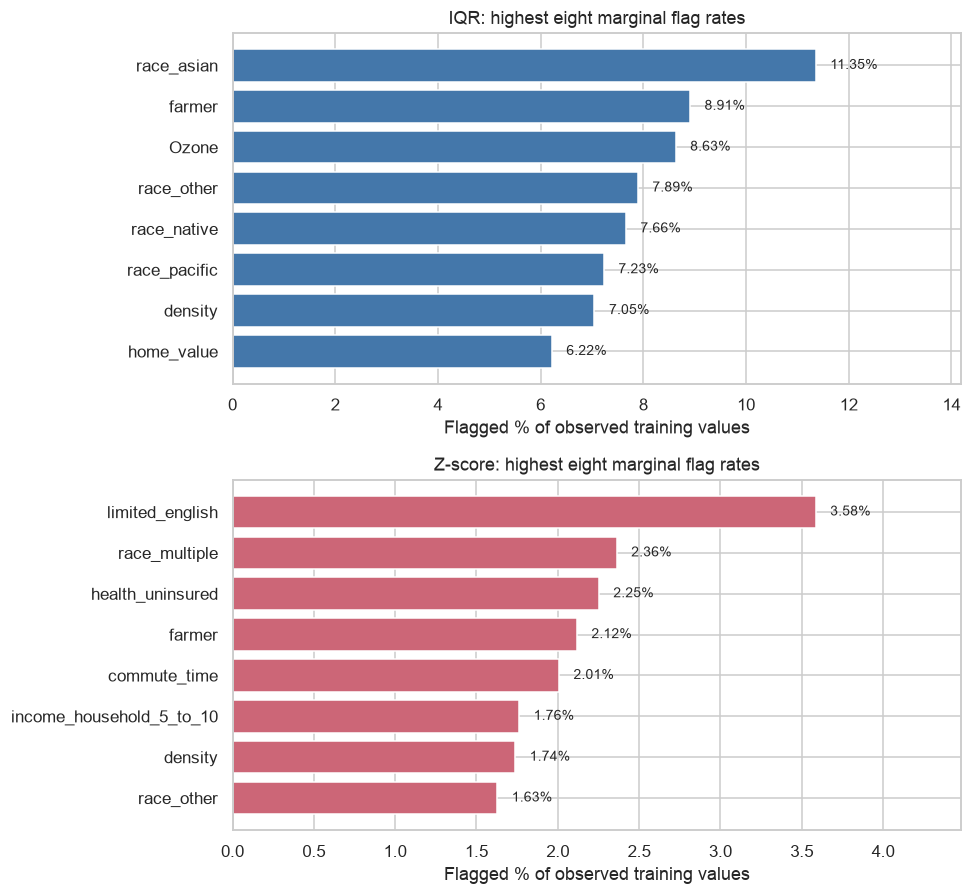

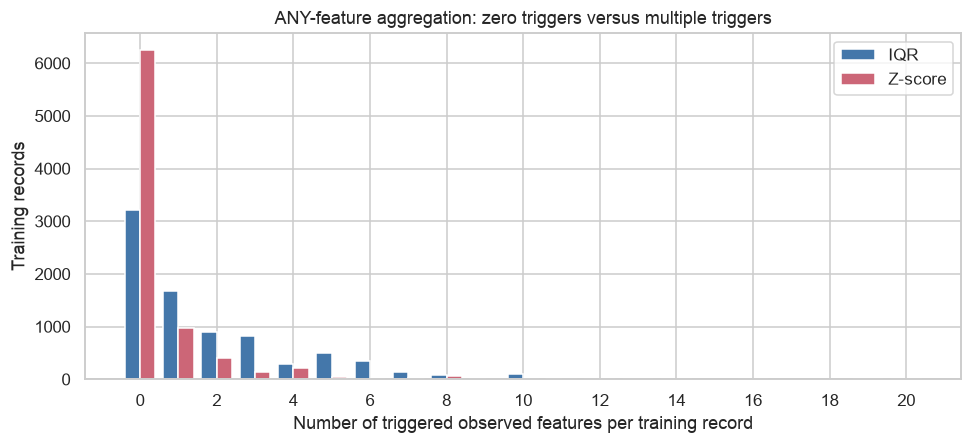

In [5]:
outlier_feature_summary = outlier_feature_audit.join(
    iqr_thresholds[["Q1", "Q3", "IQR", "Lower fence", "Upper fence"]]).join(
    zscore_parameters[["Mean", "SD (ddof 0)"]])
outlier_feature_summary = outlier_feature_summary.join([iqr_feature_counts, iqr_feature_rates, zscore_feature_counts, zscore_feature_rates])
outlier_feature_summary["IQR exception note"] = iqr_thresholds.Note
outlier_feature_summary["Z-score exception note"] = zscore_parameters.Note
display(HTML('<details><summary>All 69 features: support, fitted thresholds, counts, rates and exception notes</summary>'
    '<div style="overflow:auto;max-height:32rem">'+outlier_feature_summary.to_html(float_format="{:.5f}".format)+'</div></details>'))
outlier_comparison = pd.DataFrame([
    {"Method": name, "Rule": rule, "Eligible features": int(eligible.sum()), "Training N": len(train_index),
     "Flagged observations N": int(rows.sum()), "Flagged observations %": rows.mean()*100,
     "Would retain N": int(len(train_index)-rows.sum()), "Flagged feature-values N": int(flags.to_numpy().sum())}
    for name, rule, eligible, rows, flags in [
        ("IQR", "Outside Q1/Q3 ± 1.5 IQR", iqr_thresholds.Eligible, iqr_observation_flags, iqr_feature_flags),
        ("Z-score", "Strict |z| > 3; ddof=0", zscore_parameters.Eligible, zscore_observation_flags, zscore_feature_flags)]
]).set_index("Method")
display(HTML('<div style="overflow-x:auto">'+outlier_comparison.to_html(float_format="{:.4f}".format)+'</div>'))

outlier_groups = pd.Series("Other area context (meaning/period caveats retained)", index=outlier_features)
outlier_groups.loc[["patient_age", "bmi"]] = "Individual measurements"
outlier_groups.loc[list(air_features)] = "Annual ZIP3 air context"
outlier_groups.loc[list(bounded_share_features)] = "Bounded area shares"
outlier_group_summary = pd.DataFrame([
    {"Feature group": group, "Features N": len(columns), "Observed feature-values N": int(outlier_train_original[columns].count().sum()),
     "IQR flagged feature-values N": int(iqr_feature_flags[columns].to_numpy().sum()),
     "Z-score flagged feature-values N": int(zscore_feature_flags[columns].to_numpy().sum())}
    for group, columns in outlier_groups.groupby(outlier_groups, sort=True).groups.items()]).set_index("Feature group")
display(HTML('<div style="overflow-x:auto">'+outlier_group_summary.to_html()+'</div>'))

fig, axes = plt.subplots(2, 1, figsize=(9, 8.3))
for ax, label, rates in [(axes[0], "IQR", iqr_feature_rates), (axes[1], "Z-score", zscore_feature_rates)]:
    selected = rates.nlargest(8).sort_values()
    ax.barh(selected.index, selected.values, color="#4477AA" if label=="IQR" else "#CC6677")
    for y, value in enumerate(selected.values): ax.text(value+selected.max()*.025, y, f"{value:.2f}%", va="center", fontsize=9)
    ax.set(title=f"{label}: highest eight marginal flag rates", xlabel="Flagged % of observed training values")
    ax.set_xlim(0,selected.max()*1.25)
plt.tight_layout();plt.show()

outlier_trigger_distribution = pd.DataFrame({"IQR": iqr_flagged_features_per_row.value_counts(),
    "Z-score": zscore_flagged_features_per_row.value_counts()}).fillna(0).astype(int).sort_index()
fig, ax = plt.subplots(figsize=(9,4.2))
positions = outlier_trigger_distribution.index.to_numpy()
ax.bar(positions-.2,outlier_trigger_distribution.IQR,width=.4,label="IQR",color="#4477AA")
ax.bar(positions+.2,outlier_trigger_distribution["Z-score"],width=.4,label="Z-score",color="#CC6677")
ax.set(xlabel="Number of triggered observed features per training record",ylabel="Training records",
       title="ANY-feature aggregation: zero triggers versus multiple triggers")
ax.set_xticks(np.arange(0,positions.max()+1,max(1,int(positions.max()//10))))
ax.legend();plt.tight_layout();plt.show()

iqr_largest_group = outlier_group_summary["IQR flagged feature-values N"].idxmax()
zscore_largest_group = outlier_group_summary["Z-score flagged feature-values N"].idxmax()
display(HTML(
    f"<p><strong>Preliminary interpretation:</strong> IQR flags {int(iqr_observation_flags.sum()):,} records "
    f"({iqr_observation_flags.mean()*100:.2f}%); Z-score flags {int(zscore_observation_flags.sum()):,} "
    f"({zscore_observation_flags.mean()*100:.2f}%). Largest feature-value contribution: IQR={iqr_largest_group}; "
    f"Z-score={zscore_largest_group}. Group totals also reflect how many columns a group contains.</p>"
    f"<p>For race_pacific, observed-training skewness={outlier_feature_summary.loc['race_pacific','Skewness (observed train)']:.2f}; "
    f"IQR flags {iqr_feature_rates['race_pacific']:.2f}% versus Z-score {zscore_feature_rates['race_pacific']:.2f}%. "
    "This discrepancy is consistent with the different tail sensitivity of quartiles versus mean/SD, "
    "not a separate test identifying its cause. Extreme values can be legitimate; repeated ZIP context and overlapping shares "
    "can multiply flags without providing independent evidence of error. No clinical validity or removal benefit is established.</p>"))

### Isolation Forest

In [6]:
import warnings
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from scipy.stats import ks_2samp

STAGE03_SEED = 42
STAGE03_ORDER = ["IQR", "Z-score", "IF .01", "IF .05", "IF .10", "LOF 10", "LOF 20", "LOF 50", "DBSCAN"]
KS_ECDF_FEATURES = ["bmi", "density"]
KS_ECDF_POLICIES = ["IQR", "IF .05", "LOF 20", "DBSCAN"]
stage03_X = outlier_common_train_z.to_numpy(copy=True)
stage03_models, stage03_labels, stage03_flags = {}, {}, {}
stage03_parameters, stage03_runtimes, stage03_warnings = {}, {}, []
stage03_if_scores, stage03_if_decisions = {}, {}
stage03_duplicate_rows = int(outlier_common_train_z.duplicated().sum())
stage03_max_duplicate_multiplicity = int(outlier_common_train_z.value_counts().max())
display(pd.Series({"Training rows":len(train_index),"Shared features":len(outlier_features),
    "Additional identical rows in complete representation":stage03_duplicate_rows,
    "Maximum identical-row multiplicity":stage03_max_duplicate_multiplicity}).to_frame("Geometry audit"))
for contamination in [.01,.05,.10]:
    name=f"IF {contamination:.2f}".replace("0.",".")
    model=IsolationForest(n_estimators=100,max_samples="auto",contamination=contamination,
                          max_features=1.,bootstrap=False,random_state=STAGE03_SEED,n_jobs=1)
    with threadpool_limits(limits=1):
        start=perf_counter();model.fit(stage03_X)
        labels=model.predict(stage03_X)
        scores=model.score_samples(stage03_X);decisions=model.decision_function(stage03_X)
        elapsed=perf_counter()-start
    stage03_models[name],stage03_labels[name]=model,pd.Series(labels,index=train_index)
    stage03_flags[name]=pd.Series(labels==-1,index=train_index,dtype=bool)
    stage03_if_scores[name]=pd.Series(scores,index=train_index)
    stage03_if_decisions[name]=pd.Series(decisions,index=train_index)
    stage03_parameters[name]=f"contamination={contamination:.2f}; trees=100; samples={model.max_samples_}; seed=42"
    stage03_runtimes[name]=elapsed
display(pd.DataFrame([{"Method":name,"Offset":stage03_models[name].offset_,
    "Flagged N":int(stage03_flags[name].sum()),"Flagged %":stage03_flags[name].mean()*100,
    "Runtime (s)":stage03_runtimes[name]} for name in STAGE03_ORDER[2:5]]).set_index("Method").round(6))
stage03_if_identical_ranking = all(np.array_equal(stage03_if_scores["IF .01"],stage03_if_scores[name]) for name in ["IF .05","IF .10"])
print("Identical raw Isolation Forest scores across contamination settings:",stage03_if_identical_ranking)

,Geometry audit
Training rows,8173
Shared features,69
Additional identical rows in complete representation,1592
Maximum identical-row multiplicity,11


,Offset,Flagged N,Flagged %,Runtime (s)
Method,,,,
IF .01,-0.557097,81,0.991068,0.173723
IF .05,-0.509531,406,4.967576,0.176630
IF .10,-0.489674,817,9.996329,0.170469


Identical raw Isolation Forest scores across contamination settings: True


### Local Outlier Factor

In [7]:
stage03_lof_scores = {}
for k in [10,20,50]:
    name=f"LOF {k}"
    model=LocalOutlierFactor(n_neighbors=k,contamination="auto",novelty=False,
                            algorithm="brute",metric="euclidean",n_jobs=1)
    with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB),warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start=perf_counter();labels=model.fit_predict(stage03_X);elapsed=perf_counter()-start
    for warning in caught:stage03_warnings.append({"Method":name,"Warning":str(warning.message)})
    scores=model.negative_outlier_factor_.copy()
    stage03_models[name],stage03_labels[name]=model,pd.Series(labels,index=train_index)
    stage03_flags[name]=pd.Series(labels==-1,index=train_index,dtype=bool)
    stage03_lof_scores[name]=pd.Series(scores,index=train_index)
    stage03_parameters[name]=f"neighbors={model.n_neighbors_}; contamination=auto; Euclidean; novelty=False"
    stage03_runtimes[name]=elapsed
display(pd.DataFrame([{"Method":name,"Actual neighbors":stage03_models[name].n_neighbors_,
    "Offset":stage03_models[name].offset_,"Flagged N":int(stage03_flags[name].sum()),
    "Flagged %":stage03_flags[name].mean()*100,"Runtime (s)":stage03_runtimes[name]} for name in STAGE03_ORDER[5:8]]).set_index("Method").round(6))
if stage03_warnings:display(pd.DataFrame(stage03_warnings))
else:print("No LOF fit warnings recorded; this does not validate neighborhood geometry.")

,Actual neighbors,Offset,Flagged N,Flagged %,Runtime (s)
Method,,,,,
LOF 10,10,-1.5,1691,20.690077,0.180131
LOF 20,20,-1.5,1536,18.793589,0.185803
LOF 50,50,-1.5,1220,14.927199,0.244271


No LOF fit warnings recorded; this does not validate neighborhood geometry.


### DBSCAN calibration

,Training k-distance
0.00,0.081496
0.05,0.329822
0.25,0.677823
0.50,1.312577
0.75,3.865238
0.95,6.753287
0.99,10.567842
1.00,22.636713


,DBSCAN calibration / feasibility
min_samples (includes self),2.000000e+01
Selected eps,6.892189e+00
Algorithmic knee rank (zero-based),7.821000e+03
Maximum normalized chord gap,6.550920e-01
Radius edges including self,6.127787e+06
Mean neighbors within eps,7.497598e+02
Maximum neighbors within eps,2.579000e+03
Estimated peak allocation MiB (not measured RSS),3.365564e+02
Conservative available-memory budget MiB,1.248785e+03
Full-data neighbor diagnostic seconds,4.590247e-01


Selection rule: first maximum below endpoint chord


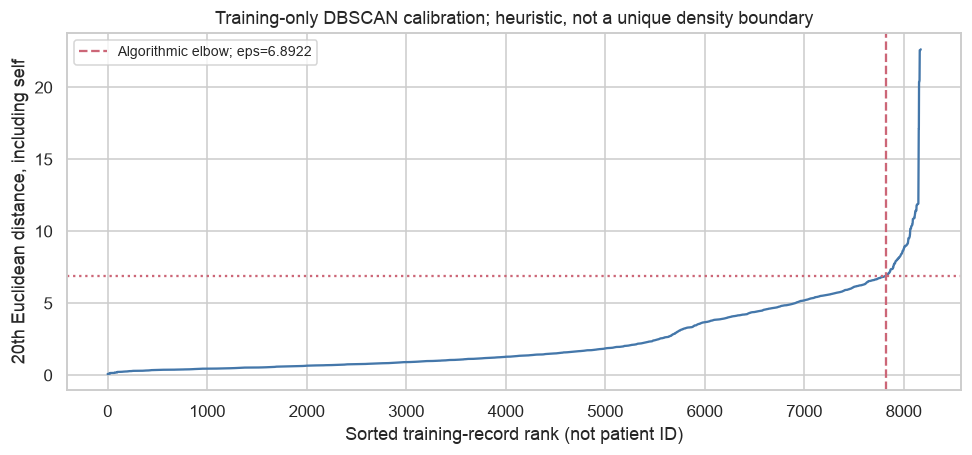

In [8]:
DBSCAN_MIN_SAMPLES=20

def select_dbscan_eps(k_distances):
    """First maximum below the normalized endpoint chord; no outlier counts enter selection."""
    ordered=np.sort(np.asarray(k_distances,dtype=float))
    if len(ordered)<3 or not np.isfinite(ordered).all() or (ordered<0).any():
        raise ValueError("Need at least three finite nonnegative k-distances")
    rank=np.linspace(0.,1.,len(ordered));span=ordered[-1]-ordered[0]
    gap=rank-(ordered-ordered[0])/span if span>0 else np.zeros_like(rank)
    knee=int(np.argmax(gap));eps=float(ordered[knee]);rule="first maximum below endpoint chord"
    if span==0:rule="flat curve: common distance; no identifiable elbow"
    if eps<=0:
        positive=ordered[ordered>0];eps=float(positive[0]) if len(positive) else float(np.finfo(float).eps)
        rule+="; zero-distance fallback as declared"
    return eps,knee,float(gap[knee]),rule

stage03_neighbors=NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES,algorithm="brute",metric="euclidean",n_jobs=1)
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start=perf_counter();stage03_neighbors.fit(stage03_X)
    stage03_distances,stage03_neighbor_indices=stage03_neighbors.kneighbors(stage03_X,return_distance=True)
    stage03_k_distances=pd.Series(stage03_distances[:,-1],index=train_index,name="20th distance including self")
    DBSCAN_EPS,stage03_knee_rank,stage03_knee_gap,stage03_eps_rule=select_dbscan_eps(stage03_k_distances)
    stage03_radius_counts=np.empty(len(train_index),dtype=np.int64)
    for start_row in range(0,len(train_index),256):
        stop_row=min(start_row+256,len(train_index))
        neighbors=stage03_neighbors.radius_neighbors(stage03_X[start_row:stop_row],radius=DBSCAN_EPS,return_distance=False)
        stage03_radius_counts[start_row:stop_row]=[len(row) for row in neighbors]
    stage03_neighbor_seconds=perf_counter()-start
del stage03_distances,stage03_neighbor_indices,neighbors
stage03_radius_edges=int(stage03_radius_counts.sum())
stage03_dbscan_peak_estimate_mib=3*stage03_radius_edges*8/1024**2+stage03_X.nbytes/1024**2+KNN_MEMORY_MIB+64
stage03_available_gib=memory_reclaimable
if sys.platform=="darwin":
    vm=subprocess.check_output(["vm_stat"],text=True)
    page_size=int(re.search(r"page size of (\d+) bytes",vm).group(1))
    stage03_available_gib=sum(int(re.search(rf"Pages {key}:\s+(\d+)",vm).group(1)) for key in ["free","inactive","speculative"])*page_size/1024**3
stage03_dbscan_budget_mib=min(memory_total*1024*.25,stage03_available_gib*1024*.75)
stage03_dbscan_feasibility=pd.Series({"min_samples (includes self)":DBSCAN_MIN_SAMPLES,
    "Selected eps":DBSCAN_EPS,"Algorithmic knee rank (zero-based)":stage03_knee_rank,
    "Maximum normalized chord gap":stage03_knee_gap,"Radius edges including self":stage03_radius_edges,
    "Mean neighbors within eps":stage03_radius_counts.mean(),"Maximum neighbors within eps":stage03_radius_counts.max(),
    "Estimated peak allocation MiB (not measured RSS)":stage03_dbscan_peak_estimate_mib,
    "Conservative available-memory budget MiB":stage03_dbscan_budget_mib,"Full-data neighbor diagnostic seconds":stage03_neighbor_seconds})
display(stage03_k_distances.quantile([0,.05,.25,.5,.75,.95,.99,1.]).rename("Training k-distance").to_frame())
display(stage03_dbscan_feasibility.to_frame("DBSCAN calibration / feasibility"))
print("Selection rule:",stage03_eps_rule)
fig,ax=plt.subplots(figsize=(9,4.3))
ax.plot(np.sort(stage03_k_distances),color="#4477AA")
ax.axvline(stage03_knee_rank,color="#CC6677",linestyle="--",label=f"Algorithmic elbow; eps={DBSCAN_EPS:.4f}")
ax.axhline(DBSCAN_EPS,color="#CC6677",linestyle=":")
ax.set(xlabel="Sorted training-record rank (not patient ID)",ylabel="20th Euclidean distance, including self",
       title="Training-only DBSCAN calibration; heuristic, not a unique density boundary")
ax.legend(fontsize=9);plt.tight_layout();plt.show()

### Primary DBSCAN fit

In [9]:
if not np.isfinite(stage03_dbscan_budget_mib) or stage03_dbscan_peak_estimate_mib>stage03_dbscan_budget_mib:
    raise MemoryError(f"DBSCAN estimated {stage03_dbscan_peak_estimate_mib:.1f} MiB exceeds observed budget {stage03_dbscan_budget_mib:.1f} MiB; no eps retuning performed")
stage03_dbscan=DBSCAN(eps=DBSCAN_EPS,min_samples=DBSCAN_MIN_SAMPLES,metric="euclidean",algorithm="brute",n_jobs=1)
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start=perf_counter();db_labels=stage03_dbscan.fit_predict(stage03_X);elapsed=perf_counter()-start
stage03_models["DBSCAN"],stage03_labels["DBSCAN"]=stage03_dbscan,pd.Series(db_labels,index=train_index)
stage03_flags["DBSCAN"]=pd.Series(db_labels==-1,index=train_index,dtype=bool)
stage03_parameters["DBSCAN"]=f"eps={DBSCAN_EPS:.8g}; min_samples=20 incl. self; Euclidean"
stage03_runtimes["DBSCAN"]=elapsed
stage03_dbscan_clusters=int(len(set(db_labels)-{-1}))
stage03_dbscan_summary=pd.Series({"Clusters (excluding noise)":stage03_dbscan_clusters,
    "Core records":len(stage03_dbscan.core_sample_indices_),"Noise N":int(stage03_flags["DBSCAN"].sum()),
    "Noise %":stage03_flags["DBSCAN"].mean()*100,"Runtime (s)":elapsed})
display(stage03_dbscan_summary.to_frame("Primary DBSCAN result"))
display(stage03_labels["DBSCAN"].value_counts().sort_index().rename("Records per cluster label (-1 = noise)").to_frame())
print("Noise degeneracy:","all noise" if stage03_flags["DBSCAN"].all() else "no noise" if not stage03_flags["DBSCAN"].any() else "neither all nor no noise")

,Primary DBSCAN result
Clusters (excluding noise),16.000000
Core records,7822.000000
Noise N,291.000000
Noise %,3.560504
Runtime (s),0.256383


,Records per cluster label (-1 = noise)
-1,291
0,7031
1,239
2,171
3,49
4,49
5,32
6,30
7,49
8,57


Noise degeneracy: neither all nor no noise


## Results

Report all nine flag rates, the full Jaccard matrix and independent hypothetical-removal
summaries. The ECDF illustration uses the original fixed BMI/density features and four
policies; all 621 KS comparisons remain available in the expandable results.

### Nine-configuration comparison

,Parameters,Feature scope,Training N,Flagged N,Flagged %,Would retain N,Runtime (s),Status
Method,,,,,,,,
IQR,linear quartiles; strict 1.5 IQR; ANY observed feature,69; observed-only,8173,4953,60.6020,3220,not timed in Part 1,PASS
Z-score,observed train mean/SD; ddof=0; strict |z|>3; ANY,69; observed-only,8173,1915,23.4308,6258,not timed in Part 1,PASS
IF .01,contamination=0.01; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,81,0.9911,8092,0.1737,PASS
IF .05,contamination=0.05; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,406,4.9676,7767,0.1766,PASS
IF .10,contamination=0.10; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,817,9.9963,7356,0.1705,PASS
LOF 10,neighbors=10; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1691,20.6901,6482,0.1801,PASS
LOF 20,neighbors=20; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1536,18.7936,6637,0.1858,PASS
LOF 50,neighbors=50; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1220,14.9272,6953,0.2443,PASS
DBSCAN,eps=6.8921891; min_samples=20 incl. self; Euclidean,69; shared kNN10/train z,8173,291,3.5605,7882,0.2564,PASS


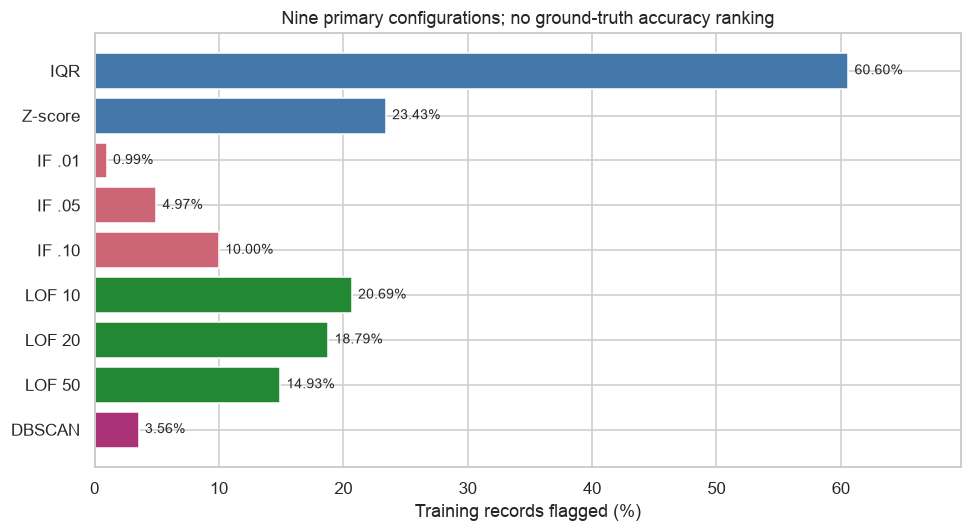

In [10]:
stage03_flags["IQR"],stage03_flags["Z-score"]=iqr_observation_flags.copy(),zscore_observation_flags.copy()
stage03_parameters["IQR"]="linear quartiles; strict 1.5 IQR; ANY observed feature"
stage03_parameters["Z-score"]="observed train mean/SD; ddof=0; strict |z|>3; ANY"
all_outlier_flags=pd.DataFrame({name:stage03_flags[name] for name in STAGE03_ORDER},index=train_index)
assert all_outlier_flags.shape==(len(train_index),9) and not all_outlier_flags.isna().any().any()
stage03_full_comparison=pd.DataFrame([{"Method":name,"Parameters":stage03_parameters[name],
    "Feature scope":"69; observed-only" if name in ["IQR","Z-score"] else "69; shared kNN10/train z",
    "Training N":len(train_index),"Flagged N":int(all_outlier_flags[name].sum()),
    "Flagged %":all_outlier_flags[name].mean()*100,"Would retain N":int((~all_outlier_flags[name]).sum()),
    "Runtime (s)":stage03_runtimes.get(name,np.nan),"Status":"PASS"} for name in STAGE03_ORDER]).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_full_comparison.to_html(float_format="{:.4f}".format,na_rep="not timed in Part 1")+'</div>'))
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(STAGE03_ORDER,stage03_full_comparison["Flagged %"],color=["#4477AA"]*2+["#CC6677"]*3+["#228833"]*3+["#AA3377"])
ax.invert_yaxis()
for i,value in enumerate(stage03_full_comparison["Flagged %"]):ax.text(value+.5,i,f"{value:.2f}%",va="center",fontsize=9)
ax.set_xlim(0,max(10,stage03_full_comparison["Flagged %"].max()*1.15))
ax.set(xlabel="Training records flagged (%)",title="Nine primary configurations; no ground-truth accuracy ranking")
plt.tight_layout();plt.show()

### Jaccard agreement

,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,1.000,0.387,0.016,0.082,0.165,0.187,0.172,0.158,0.059
Z-score,0.387,1.000,0.042,0.192,0.334,0.134,0.158,0.172,0.142
IF .01,0.016,0.042,1.000,0.200,0.099,0.021,0.035,0.024,0.240
IF .05,0.082,0.192,0.200,1.000,0.497,0.056,0.068,0.088,0.305
IF .10,0.165,0.334,0.099,0.497,1.000,0.081,0.079,0.172,0.197
LOF 10,0.187,0.134,0.021,0.056,0.081,1.000,0.380,0.154,0.053
LOF 20,0.172,0.158,0.035,0.068,0.079,0.380,1.000,0.279,0.115
LOF 50,0.158,0.172,0.024,0.088,0.172,0.154,0.279,1.000,0.120
DBSCAN,0.059,0.142,0.240,0.305,0.197,0.053,0.115,0.120,1.000


,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,4953,1915,81,406,817,1046,953,841,291
Z-score,1915,1915,81,374,684,427,470,461,275
IF .01,81,81,81,81,81,36,55,31,72
IF .05,406,374,81,406,406,111,123,131,163
IF .10,817,684,81,406,817,188,172,299,182
LOF 10,1046,427,36,111,188,1691,889,389,99
LOF 20,953,470,55,123,172,889,1536,602,188
LOF 50,841,461,31,131,299,389,602,1220,162
DBSCAN,291,275,72,163,182,99,188,162,291


,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,4953,4953,4953,4953,4953,5598,5536,5332,4953
Z-score,4953,1915,1915,1947,2048,3179,2981,2674,1931
IF .01,4953,1915,81,406,817,1736,1562,1270,300
IF .05,4953,1947,406,406,817,1986,1819,1495,534
IF .10,4953,2048,817,817,817,2320,2181,1738,926
LOF 10,5598,3179,1736,1986,2320,1691,2338,2522,1883
LOF 20,5536,2981,1562,1819,2181,2338,1536,2154,1639
LOF 50,5332,2674,1270,1495,1738,2522,2154,1220,1349
DBSCAN,4953,1931,300,534,926,1883,1639,1349,291


,Method A,Method B,Intersection N,Union N,Jaccard
21,IF .05,IF .10,406,817,0.49694
0,IQR,Z-score,1915,4953,0.38663
30,LOF 10,LOF 20,889,2338,0.38024


,Method A,Method B,Intersection N,Union N,Jaccard
1,IQR,IF .01,81,4953,0.01635
17,IF .01,LOF 10,36,1736,0.02074
19,IF .01,LOF 50,31,1270,0.02441


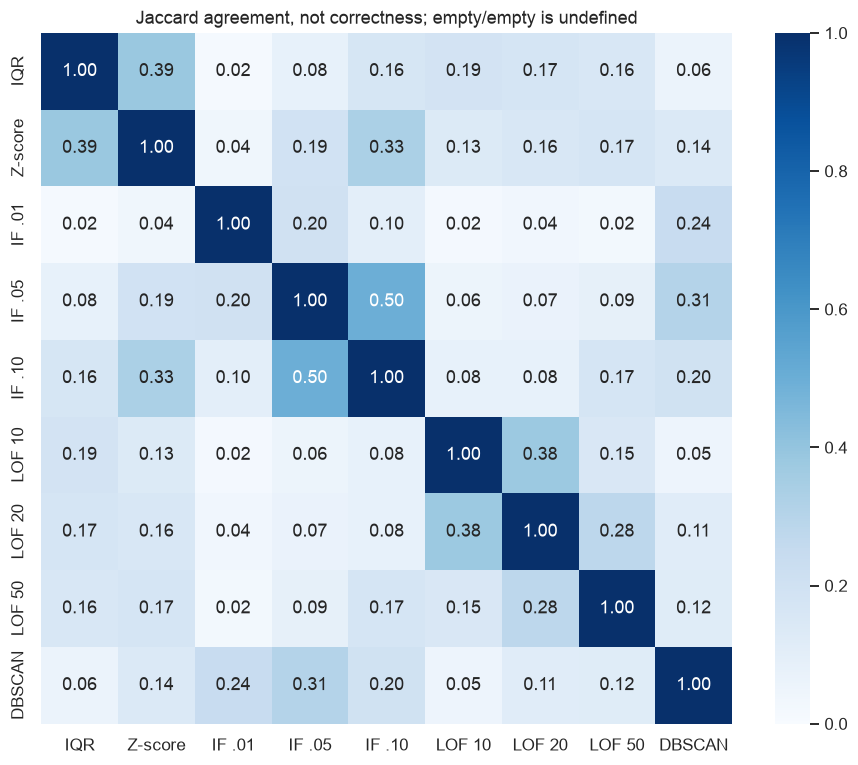

In [11]:
def jaccard_matrices(flag_frame):
    """Aligned Boolean frame -> Jaccard, intersection and union matrices; empty/empty is NaN."""
    if not flag_frame.index.is_unique or flag_frame.isna().any().any() or not flag_frame.dtypes.eq(bool).all():
        raise ValueError("Need unique row identities and nonmissing Boolean flags")
    binary=flag_frame.to_numpy(dtype=np.int64)
    intersection=binary.T@binary
    sizes=binary.sum(axis=0);union=sizes[:,None]+sizes[None,:]-intersection
    similarity=np.divide(intersection,union,out=np.full(union.shape,np.nan,dtype=float),where=union>0)
    names=flag_frame.columns
    return (pd.DataFrame(similarity,index=names,columns=names),pd.DataFrame(intersection,index=names,columns=names),
            pd.DataFrame(union,index=names,columns=names))

stage03_jaccard,stage03_intersections,stage03_unions=jaccard_matrices(all_outlier_flags)
stage03_pair_rows=[]
for i,left in enumerate(STAGE03_ORDER):
    for right in STAGE03_ORDER[i+1:]:
        stage03_pair_rows.append({"Method A":left,"Method B":right,"Intersection N":int(stage03_intersections.loc[left,right]),
            "Union N":int(stage03_unions.loc[left,right]),"Jaccard":stage03_jaccard.loc[left,right]})
stage03_pairs=pd.DataFrame(stage03_pair_rows)
display(stage03_jaccard.style.format("{:.3f}",na_rep="undefined"))
for label,matrix in [("Intersections: all 9×9 counts",stage03_intersections),("Unions: all 9×9 counts",stage03_unions)]:
    display(HTML('<details><summary>'+label+'</summary><div style="overflow:auto">'+matrix.to_html()+'</div></details>'))
stage03_highest_pairs=stage03_pairs.dropna(subset=["Jaccard"]).sort_values("Jaccard",ascending=False,kind="stable").head(3)
stage03_lowest_pairs=stage03_pairs.dropna(subset=["Jaccard"]).sort_values("Jaccard",kind="stable").head(3)
display(stage03_highest_pairs.round(5));display(stage03_lowest_pairs.round(5))
fig,ax=plt.subplots(figsize=(8.5,7))
sns.heatmap(stage03_jaccard,annot=True,fmt=".2f",vmin=0,vmax=1,cmap="Blues",mask=stage03_jaccard.isna(),square=True,ax=ax)
ax.set(title="Jaccard agreement, not correctness; empty/empty is undefined")
plt.tight_layout();plt.show()

### Hypothetical sample composition

In [12]:
stage03_retained_training={}
stage03_treatment_rows=[]
stage03_training_zips=df.loc[train_index,ZIP]
for name in STAGE03_ORDER:
    retained=outlier_train_original.loc[~all_outlier_flags[name]].copy(deep=True)
    stage03_retained_training[name]=retained
    remaining_zips=int(stage03_training_zips.loc[retained.index].nunique())
    stage03_treatment_rows.append({"Method":name,"Original N":len(train_index),"Removed N":int(all_outlier_flags[name].sum()),
        "Retained N":len(retained),"Retention %":len(retained)/len(train_index)*100,
        "ZIP groups before":stage03_training_zips.nunique(),"ZIP groups retained":remaining_zips,
        "ZIP groups lost":int(stage03_training_zips.nunique()-remaining_zips),
        "BMI observed before":int(outlier_train_original.bmi.count()),"BMI observed retained":int(retained.bmi.count()),
        "BMI missing % retained":retained.bmi.isna().mean()*100 if len(retained) else np.nan,
        "All cells missing % retained":retained.isna().to_numpy().mean()*100 if len(retained) else np.nan})
stage03_treatment_summary=pd.DataFrame(stage03_treatment_rows).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_treatment_summary.to_html(float_format="{:.4f}".format)+'</div>'))
print(f"Reference BMI missing%={outlier_train_original.bmi.isna().mean()*100:.4f}; all-cell missing%={outlier_original_missing.to_numpy().mean()*100:.4f}.")

,Original N,Removed N,Retained N,Retention %,ZIP groups before,ZIP groups retained,ZIP groups lost,BMI observed before,BMI observed retained,BMI missing % retained,All cells missing % retained
Method,,,,,,,,,,,
IQR,8173,4953,3220,39.3980,443,124,319,2531,945,70.6522,1.0239
Z-score,8173,1915,6258,76.5692,443,263,180,2531,1916,69.3832,1.0056
IF .01,8173,81,8092,99.0089,443,425,18,2531,2509,68.9941,1.0069
IF .05,8173,406,7767,95.0324,443,396,47,2531,2426,68.7653,1.0039
IF .10,8173,817,7356,90.0037,443,363,80,2531,2282,68.9777,1.0074
LOF 10,8173,1691,6482,79.3099,443,338,105,2531,1586,75.5322,1.1101
LOF 20,8173,1536,6637,81.2064,443,335,108,2531,1837,72.3218,1.0488
LOF 50,8173,1220,6953,85.0728,443,351,92,2531,2072,70.1999,1.0243
DBSCAN,8173,291,7882,96.4395,443,391,52,2531,2447,68.9546,0.9993


Reference BMI missing%=69.0322; all-cell missing%=1.0138.


### KS distribution impact

,Features evaluated,Unavailable features,Median KS D,Maximum KS D,Largest-shift feature,Largest-shift role,Numerical-zero p N
Method,,,,,,,
IQR,69,0,0.157277,0.243606,education_less_highschool,"Area share [0,100]",0
Z-score,69,0,0.044664,0.075565,rent_burden,Area numerical summary,0
IF .01,69,0,0.003530,0.007267,income_household_75_to_100,"Area share [0,100]",0
IF .05,69,0,0.013548,0.033769,income_household_75_to_100,"Area share [0,100]",0
IF .10,69,0,0.025702,0.053237,income_household_75_to_100,"Area share [0,100]",0
LOF 10,69,0,0.009636,0.067298,bmi,Individual BMI,0
LOF 20,69,0,0.012187,0.048877,bmi,Individual BMI,0
LOF 50,69,0,0.020538,0.039516,income_household_35_to_50,"Area share [0,100]",0
DBSCAN,69,0,0.007903,0.015522,income_household_75_to_100,"Area share [0,100]",0


Method,Feature,Semantic role,Original observed N,Retained observed N,KS D,Nominal KS p (dependent samples),p-value note,Status
IQR,patient_age,Individual age,8173,3220,0.0228734897,0.175521191,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,bmi,Individual BMI,2531,945,0.0240881848,0.810277778,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,population,Area numerical summary,8173,3220,0.191760516,7.17879968e-75,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,density,Area numerical summary,8173,3220,0.220710178,2.62792916e-99,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_median,Area numerical summary,8173,3220,0.158618592,3.10319312e-51,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_under_10,"Area share [0,100]",8173,3220,0.177737065,2.61969051e-64,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_10_to_19,"Area share [0,100]",8173,3220,0.127132172,5.25313322e-33,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_20s,"Area share [0,100]",8173,3220,0.181668317,3.47261436e-67,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_30s,"Area share [0,100]",8173,3220,0.122509201,1.13082465e-30,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_40s,"Area share [0,100]",8173,3220,0.0902147124,8.25948498e-17,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p


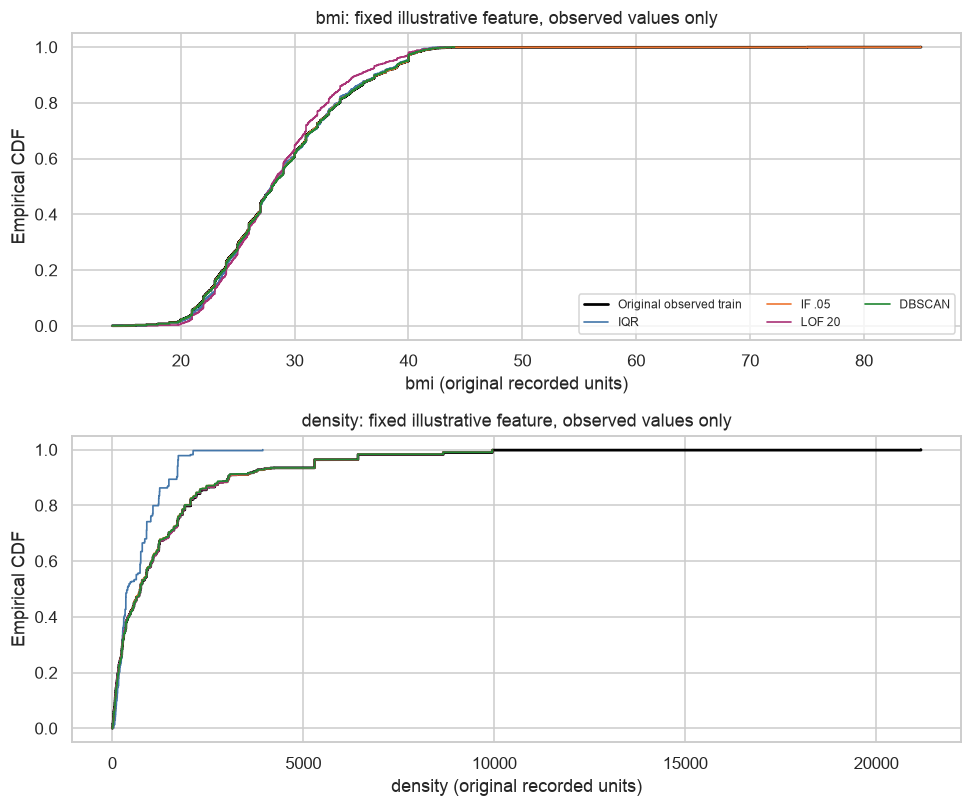

In [13]:
def ks_observed_change(before,retained):
    """Observed-only two-sided KS; nominal p-values do not fix nested-sample dependence."""
    a=before.dropna().to_numpy(dtype=float);b=retained.dropna().to_numpy(dtype=float)
    result={"Original observed N":len(a),"Retained observed N":len(b),"KS D":np.nan,
            "Nominal KS p (dependent samples)":np.nan,"p-value note":"not evaluated","Status":"NOT EVALUATED: observed N<2"}
    if len(a)<2 or len(b)<2:return result
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        result["Status"]="NOT EVALUATED: nonfinite observations";return result
    test=ks_2samp(a,b,alternative="two-sided",method="asymp")
    result.update({"KS D":float(test.statistic),"Nominal KS p (dependent samples)":float(test.pvalue),
        "p-value note":"numerical-zero/underflow; not literal zero probability" if test.pvalue==0 else "nominal only; dependence/ties not calibrated",
        "Status":"COMPUTED: descriptive D; nominal p"})
    return result

stage03_ks_rows=[]
for name in STAGE03_ORDER:
    for feature in outlier_features:
        stage03_ks_rows.append({"Method":name,"Feature":feature,
            "Semantic role":outlier_feature_audit.loc[feature,"Semantic role"],
            **ks_observed_change(outlier_train_original[feature],stage03_retained_training[name][feature])})
stage03_ks_results=pd.DataFrame(stage03_ks_rows)
stage03_ks_summary_rows=[]
for name in STAGE03_ORDER:
    rows=stage03_ks_results[stage03_ks_results.Method.eq(name)];valid=rows.dropna(subset=["KS D"])
    largest=valid.loc[valid["KS D"].idxmax()] if len(valid) else None
    stage03_ks_summary_rows.append({"Method":name,"Features evaluated":len(valid),"Unavailable features":len(rows)-len(valid),
        "Median KS D":valid["KS D"].median(),"Maximum KS D":valid["KS D"].max(),
        "Largest-shift feature":largest.Feature if largest is not None else "unavailable",
        "Largest-shift role":largest["Semantic role"] if largest is not None else "unavailable",
        "Numerical-zero p N":int(valid["Nominal KS p (dependent samples)"].eq(0).sum())})
stage03_ks_summary=pd.DataFrame(stage03_ks_summary_rows).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_ks_summary.to_html(float_format="{:.6f}".format)+'</div>'))
display(HTML('<details><summary>All 621 observed-value KS comparisons — D and nominal uncalibrated p-values</summary>'
    '<div style="overflow:auto;max-height:32rem">'+stage03_ks_results.to_html(index=False,float_format="{:.9g}".format)+'</div></details>'))
fig,axes=plt.subplots(2,1,figsize=(9,7.5))
colors={"IQR":"#4477AA","IF .05":"#EE7733","LOF 20":"#AA3377","DBSCAN":"#228833"}
for ax,feature in zip(axes,KS_ECDF_FEATURES):
    original=np.sort(outlier_train_original[feature].dropna().to_numpy())
    ax.step(original,np.arange(1,len(original)+1)/len(original),where="post",color="black",linewidth=1.8,label="Original observed train")
    for name in KS_ECDF_POLICIES:
        values=np.sort(stage03_retained_training[name][feature].dropna().to_numpy())
        if len(values):ax.step(values,np.arange(1,len(values)+1)/len(values),where="post",color=colors[name],linewidth=1.1,label=name)
    ax.set(title=f"{feature}: fixed illustrative feature, observed values only",xlabel=f"{feature} (original recorded units)",ylabel="Empirical CDF")
axes[0].legend(fontsize=8,ncol=3);plt.tight_layout();plt.show()

## Discussion

IQR flags 60.60% under the 69-feature ANY rule, versus 23.43% for Z-score. A record has
many opportunities to trigger, and repeated/compositional context can duplicate evidence.
IF contamination thresholds an identical raw-score ranking here. LOF is neighbor-sensitive;
DBSCAN's heuristic eps=6.892189 gives 16 non-noise clusters and 291 noise candidates.

IQR removal would lose 319 of 443 ZIP groups. LOF10 removal raises BMI missingness from
69.03% to 75.53%. The lowest Jaccard can still contain the entire smaller flag set; overlap
must be read alongside set sizes. These results expose selection/geometry risks without
proving their cause or demonstrating a predictive benefit from removal.

In [14]:
stage03_retention_policy={"Decision":"Preserve all original observations; retain all nine anomaly flags for investigation",
    "Automatic deletion":False,"Reason":"No verified outlier truth or demonstrated removal benefit; substantial selection/geometry risks",
    "Predictive pipeline":"Not finalized; requires fold-local downstream validation and temporal eligibility"}
stage03_adopted_training_rows=train_index.copy()
largest_pair=stage03_highest_pairs.iloc[0] if len(stage03_highest_pairs) else None
smallest_pair=stage03_lowest_pairs.iloc[0] if len(stage03_lowest_pairs) else None
display(HTML(pd.Series(stage03_retention_policy).to_frame("Treatment decision").to_html()))
display(HTML(
    f"<p><strong>Actual evidence:</strong> nine configurations flag between {stage03_full_comparison['Flagged %'].min():.2f}% "
    f"and {stage03_full_comparison['Flagged %'].max():.2f}% of the same training records. "
    f"IF raw-score equality across contamination={stage03_if_identical_ranking}; differing IF overlaps reflect thresholded sets. "
    f"The strongest reported pair is {largest_pair['Method A']} / {largest_pair['Method B']} "
    f"(J={largest_pair.Jaccard:.4f}); the weakest is {smallest_pair['Method A']} / {smallest_pair['Method B']} "
    f"(J={smallest_pair.Jaccard:.4f}). Agreement does not validate either flag set.</p>"
    f"<p>Primary DBSCAN: eps={DBSCAN_EPS:.6f}, min_samples={DBSCAN_MIN_SAMPLES}, clusters={stage03_dbscan_clusters}, "
    f"noise={stage03_full_comparison.loc['DBSCAN','Flagged %']:.2f}%. Its heuristic/radius diagnostic used all training rows, "
    f"{stage03_neighbor_seconds:.3f}s; estimated peak allocation={stage03_dbscan_peak_estimate_mib:.1f} MiB "
    f"(not measured RSS). No eps search based on noise rates was performed.</p>"
    f"<p>IQR's hypothetical removal retains {stage03_treatment_summary.loc['IQR','Retained N']} records and loses "
    f"{stage03_treatment_summary.loc['IQR','ZIP groups lost']} ZIP groups; maximum observed-feature KS D="
    f"{stage03_ks_summary.loc['IQR','Maximum KS D']:.4f}. "
    "Such sample loss/composition changes require justification beyond tail reduction. All original rows remain adopted; "
    "no candidate subset is exported or silently chosen as the predictive dataset.</p>"))

small_pair_size=min(int(all_outlier_flags[smallest_pair["Method A"]].sum()),int(all_outlier_flags[smallest_pair["Method B"]].sum()))
display(HTML(
    f"<p>The lowest-Jaccard pair shares {int(smallest_pair['Intersection N'])} of its smaller set's {small_pair_size} flags. "
    "A low ratio can coexist with complete containment when flag-set sizes differ, so it must not be described as necessarily disjoint. "
    f"LOF rates across k=10/20/50 are {stage03_full_comparison.loc['LOF 10','Flagged %']:.2f}%, "
    f"{stage03_full_comparison.loc['LOF 20','Flagged %']:.2f}% and {stage03_full_comparison.loc['LOF 50','Flagged %']:.2f}%; "
    "this observed neighborhood sensitivity is not an accuracy ranking.</p>"
    f"<p>Under LOF 10 removal, BMI missingness would change from {outlier_train_original.bmi.isna().mean()*100:.2f}% "
    f"to {stage03_treatment_summary.loc['LOF 10','BMI missing % retained']:.2f}%. "
    f"The complete representation contains {stage03_duplicate_rows} additional identical rows (maximum multiplicity "
    f"{stage03_max_duplicate_multiplicity}). These are concrete selection/geometry concerns; attributing them specifically "
    "to imputation or geography would require a separate controlled analysis, not an unsupported causal explanation.</p>"
))

,Treatment decision
Decision,Preserve all original observations; retain all nine anomaly flags for investigation
Automatic deletion,False
Reason,No verified outlier truth or demonstrated removal benefit; substantial selection/geometry risks
Predictive pipeline,Not finalized; requires fold-local downstream validation and temporal eligibility


## Conclusion

Preserve all original training observations and keep the nine flags for investigation.
No detector, agreement threshold or nominal KS p-value justifies automatic deletion here.
Original data and both holdouts remain unchanged. Continue with [Stage 04](04_scaling.ipynb).

In [15]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before, "Raw CSV changed"
print(f"Completed {len(STAGE03_ORDER)} detectors/settings, {len(stage03_pairs)} Jaccard pairs and {len(stage03_ks_results)} KS comparisons; all original training rows retained.")

Completed 9 detectors/settings, 36 Jaccard pairs and 621 KS comparisons; all original training rows retained.
